# Modelo de Ising 2D con Transformer autoregresivo



Aproximamos la distribución de Boltzmann $p_B(s)=\frac{1}{Z}e^{-E(s)/T}$ mediante una distribución variacional autoregresiva $q_\theta(s)=\prod_i q_\theta(s_i\mid s_{<i})$ implementada con un Transformer con máscara causal.



In [2]:
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

from tqdm.auto import tqdm

In [3]:
# Parámetros del modelo de Ising

L = 3
N = L * L

J = 1.0
h = 0.0
T = 2.0



device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)
print("L =", L)
print("N =", N)

Device: cpu
L = 3
N = 9


## Tokenización

Cada espín $s_i\in\{-1,+1\}$ se codifica como token (`DOWN=1`, `UP=2`). Se añade un token de inicio `BOS=0` para la secuencia desplazada $(\text{BOS},s_1,\dots,s_{N-1})$ que predice $(s_1,\dots,s_N)$.

In [4]:
BOS_TOKEN = 0
DOWN_TOKEN = 1   # spin = -1
UP_TOKEN = 2     # spin = +1

VOCAB_SIZE = 3

In [5]:
def spins_to_tokens(spins):
    """
    spins: tensor con valores {-1,+1}
    devuelve tokens {1,2}
    """
    return torch.where(
        spins == -1,
        torch.tensor(DOWN_TOKEN, device=spins.device),
        torch.tensor(UP_TOKEN, device=spins.device)
    )


def tokens_to_spins(tokens):
    """
    tokens {1,2}
    devuelve espines {-1,+1}
    """
    return torch.where(
        tokens == DOWN_TOKEN,
        torch.tensor(-1, device=tokens.device),
        torch.tensor(+1, device=tokens.device)
    )

In [6]:
def causal_mask(seq_len):

    mask = torch.triu(
        torch.ones(seq_len, seq_len),
        diagonal=1
    )

    mask = mask.masked_fill(mask == 1, float("-inf"))

    return mask

In [7]:
causal_mask(5)

tensor([[0., -inf, -inf, -inf, -inf],
        [0., 0., -inf, -inf, -inf],
        [0., 0., 0., -inf, -inf],
        [0., 0., 0., 0., -inf],
        [0., 0., 0., 0., 0.]])

## Transformer autoregresivo

- Embeddings de token + posición.
- Máscara causal: la salida en la posición $i$ depende solo de $s_{<i}$.
- Capa lineal final con 2 logits $\to$ softmax da $q_\theta(s_i\mid s_{<i})$ para $s_i\in\{-1,+1\}$.
- `dropout=0` para que muestreo y evaluación coincidan.

In [8]:
class IsingTransformer(nn.Module):

    def __init__(
        self,
        seq_len,
        d_model=64,
        nhead=4,
        num_layers=2,
        dim_feedforward=128
    ):
        super().__init__()

        self.seq_len = seq_len
        self.d_model = d_model

        self.token_embedding = nn.Embedding(
            VOCAB_SIZE,
            d_model
        )

        self.position_embedding = nn.Embedding(
            seq_len,
            d_model
        )

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=dim_feedforward,
            dropout=0.0,
            batch_first=True
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=num_layers
        )

        self.output_layer = nn.Linear(
            d_model,
            2
        )

    def forward(self, x):

        batch_size, seq_len = x.shape

        positions = torch.arange(
            seq_len,
            device=x.device
        ).unsqueeze(0)

        h = (
            self.token_embedding(x)
            + self.position_embedding(positions)
        )

        mask = causal_mask(seq_len).to(x.device)

        h = self.transformer(
            h,
            mask=mask
        )

        logits = self.output_layer(h)

        return logits

In [9]:
model = IsingTransformer(
    seq_len=N
).to(device)

x = torch.randint(
    0,
    VOCAB_SIZE,
    (2, N),
    device=device
)

logits = model(x)

print(logits.shape)

torch.Size([2, 9, 2])


## Inicialización del entrenamiento

Tamaño de lote $M=256$, tasa de aprendizaje $\eta=10^{-3}$, iteraciones $K=3000$, optimizador Adam.

In [10]:
# Hiperparámetros de entrenamiento

batch_size = 256   # M
lr = 1e-3          # eta
num_steps = 3000   # K

In [37]:
model = IsingTransformer(
    seq_len=N, d_model=64, nhead=4, num_layers=2, dim_feedforward=128
).to(device)
print("Parámetros:", sum(p.numel() for p in model.parameters()))

Parámetros: 67842


In [38]:
optimizer = torch.optim.Adam(model.parameters(), lr=lr)

## Muestreo de $q_\theta$

Generación secuencial: en cada paso se muestrea $s_i\sim q_\theta(\cdot\mid s_{<i})$ con `torch.multinomial` sin construir grafo de gradiente.

In [39]:
@torch.no_grad()
def sample_configs(model, batch_size):
    """
    Muestrea M configuraciones de q_theta.
    Índice 0 softmax -> espín -1 -> DOWN_TOKEN(1)
    Índice 1 softmax -> espín +1 -> UP_TOKEN(2)
    """
    model.eval()
    sequences = torch.full(
        (batch_size, 1), BOS_TOKEN, dtype=torch.long, device=device
    )
    for _ in range(N):
        logits = model(sequences)
        probs  = F.softmax(logits[:, -1, :], dim=-1)
        idx    = torch.multinomial(probs, 1)   # {0,1}
        token  = idx + 1                       # {1,2}
        sequences = torch.cat([sequences, token], dim=1)
    return tokens_to_spins(sequences[:, 1:])

In [40]:
samples = sample_configs(
    model,
    batch_size=5
)

print(samples)
print(samples.shape)

tensor([[-1, -1,  1, -1,  1, -1, -1,  1, -1],
        [ 1, -1,  1,  1, -1,  1, -1,  1,  1],
        [-1, -1, -1, -1, -1, -1, -1,  1,  1],
        [ 1, -1,  1, -1, -1,  1,  1, -1,  1],
        [ 1, -1, -1, -1, -1, -1,  1, -1, -1]])
torch.Size([5, 9])


In [41]:
config = samples[0].cpu().numpy()

config = config.reshape(L, L)

print(config)

[[-1 -1  1]
 [-1  1 -1]
 [-1  1 -1]]


## Energía del modelo de Ising

$$E(s)=-J\sum_{\langle i,j\rangle}s_i s_j - h\sum_i s_i$$

En red cuadrada $L\times L$ con condiciones periódicas (`torch.roll`), cada par de primeros vecinos se cuenta una vez.

In [42]:
def ising_energy(spins, L, J=1.0, h=0.0):
    """
    spins: (batch_size, N)
           con valores {-1,+1}

    retorna:
        energy: (batch_size,)
    """

    batch_size = spins.shape[0]

    lattice = spins.reshape(batch_size, L, L)

    right = torch.roll(
        lattice,
        shifts=-1,
        dims=2
    )

    down = torch.roll(
        lattice,
        shifts=-1,
        dims=1
    )

    interaction = (
        lattice * right +
        lattice * down
    )

    E_int = -J * interaction.sum(dim=(1, 2))

    E_field = -h * lattice.sum(dim=(1, 2))

    return E_int + E_field

In [43]:
test = torch.ones(
    (1, N),
    device=device
)

E = ising_energy(
    test,
    L,
    J,
    h
)

print(E)

tensor([-18.])


## Log-probabilidad de una configuración

Con las salidas del Transformer y `log_softmax`, se selecciona el logit del espín observado en cada posición y se suma:
$$\ln q_\theta(s)=\sum_{i=1}^N \ln q_\theta(s_i\mid s_{<i}).$$

In [44]:
def build_sequences(spins):

    spin_tokens = spins_to_tokens(spins)

    batch_size = spins.shape[0]

    bos = torch.full(
        (batch_size, 1),
        BOS_TOKEN,
        dtype=torch.long,
        device=spins.device
    )

    inputs = torch.cat(
        [bos, spin_tokens[:, :-1]],
        dim=1
    )

    targets = spin_tokens

    return inputs, targets

In [45]:
def log_probability(model, spins):

    inputs, targets = build_sequences(spins)

    logits = model(inputs)

    log_probs = F.log_softmax(
        logits,
        dim=-1
    )

    target_index = targets - 1

    selected = log_probs.gather(
        dim=2,
        index=target_index.unsqueeze(-1)
    ).squeeze(-1)

    return selected.sum(dim=1)

In [46]:
samples = sample_configs(
    model,
    batch_size=10
)

log_q = log_probability(
    model,
    samples
)

print(log_q.shape)
print(log_q[:5])

torch.Size([10])
tensor([-8.6385, -4.2076, -8.8831, -6.3683, -4.2246], grad_fn=<SliceBackward0>)


In [47]:
def estimate_observables(
    model,
    samples,
    T,
    L,
    J=1.0,
    h=0.0
):

    energies = ising_energy(
        samples,
        L,
        J,
        h
    )

    log_q = log_probability(
        model,
        samples
    )

    f = energies + T * log_q

    F_est = f.mean()

    U_est = energies.mean()

    S_est = -log_q.mean()

    return (
        F_est,
        U_est,
        S_est,
        energies,
        log_q,
        f
    )

In [48]:
samples = sample_configs(
    model,
    batch_size
)

F_est, U_est, S_est, E, log_q, f = (
    estimate_observables(
        model,
        samples,
        T,
        L,
        J,
        h
    )
)

print("F =", F_est.item())
print("U =", U_est.item())
print("S =", S_est.item())

F = -9.982081413269043
U = 0.96875
S = 5.47541618347168


## Validación por enumeración exacta

Para $L=3$ hay $2^9=512$ configuraciones. Calculamos
$$Z=\sum_s e^{-E(s)/T},\qquad F_B=-T\ln Z,$$
y la distribución de Boltzmann exacta $\ln p_B(s)=-\frac{E(s)}{T}-\ln Z$ para comparar con $q_\theta$.

In [49]:
def exact_enumeration(L, J=1.0, h=0.0, T=2.0):
    N = L * L
    all_spins = torch.tensor(
        [[1 - 2 * ((k >> i) & 1) for i in range(N)] for k in range(2 ** N)],
        dtype=torch.float32, device=device,
    )
    E_all  = ising_energy(all_spins, L, J, h)
    log_w  = -E_all / T
    log_Z  = torch.logsumexp(log_w, dim=0)
    F_B    = -T * log_Z
    log_pB = log_w - log_Z
    return all_spins, E_all, log_Z, F_B, log_pB

all_spins, E_all, log_Z, F_B, log_pB = exact_enumeration(L, J, h, T)
print(f"Z   = {log_Z.exp().item():.6f}")
print(f"F_B = {F_B.item():.6f}  |  F_B/N = {(F_B / N).item():.6f}")

Z   = 20437.974609
F_B = -19.850300  |  F_B/N = -2.205589


## Entrenamiento variacional

En cada iteración:
1. Muestrear $s^{(m)}\sim q_\theta$, $m=1,\dots,M$.
2. Calcular $E_m$ y $\ell_m=\ln q_\theta(s^{(m)})$.
3. Estimar $f_m=E_m+T\ell_m$ y $\hat F_\theta=\frac{1}{M}\sum_m f_m$.
4. Gradiente vía función auxiliar $\mathcal{L}_{\text{aux}}=\frac{1}{M}\sum_m \text{stopgrad}(f_m)\,\ell_m$, pues $\nabla_\theta\mathcal{L}_{\text{aux}}=\hat g_\theta$.
5. Actualizar $\theta\leftarrow\theta-\eta\hat g_\theta$ con Adam.

In [50]:
history = {"F": [], "U": [], "S": []}

for step in tqdm(range(num_steps), desc="training"):
    #  Muestrear con θ actual
    samples = sample_configs(model, batch_size)

    #  Energía
    energies = ising_energy(samples, L, J, h).detach()

    # log q_θ(s) con grad
    model.train()
    log_q = log_probability(model, samples)

    # f_m = E_m + T·ℓ_m  con stopgrad
    f     = energies + T * log_q.detach()
    F_est = f.mean()

    # L_aux = mean( stopgrad(f_m)·ℓ_m )
    L_aux = (f * log_q).mean()

    # Actualizar
    optimizer.zero_grad()
    L_aux.backward()
    optimizer.step()

    if step % 50 == 0:
        history["F"].append(F_est.item())
        history["U"].append(energies.mean().item())
        history["S"].append(-log_q.detach().mean().item())

print(f"F̂ final = {F_est.item():.4f}   F_B = {F_B.item():.4f}")

training:   0%|          | 0/3000 [00:00<?, ?it/s]

F̂ final = -19.6548   F_B = -19.8503


## Verificaciones

- Normalización: $\sum_s q_\theta(s)=1$.
- Cota variacional: $F_\theta\ge F_B$.
- Divergencia KL: $D_{\text{KL}}(q_\theta\|p_B)=\frac{F_\theta-F_B}{T}$.

In [51]:
model.train()
with torch.no_grad():
    log_q_all = log_probability(model, all_spins)
q_all = log_q_all.exp()

print(f"Σ_s qθ(s)    = {q_all.sum().item():.6f}")           # ≈ 1
print(f"F̂/N          = {(F_est / N).item():.6f}")
print(f"F_B/N        = {(F_B / N).item():.6f}")
print(f"F̂ ≥ F_B      ? {F_est.item() >= F_B.item()}")

KL = (q_all * (log_q_all - log_pB)).sum()
print(f"D_KL(q||p_B) = {KL.item():.6f}")
print(f"(F̂−F_B)/T    = {((F_est - F_B) / T).item():.6f}")   # ≈ KL

Σ_s qθ(s)    = 1.000000
F̂/N          = -2.183872
F_B/N        = -2.205589
F̂ ≥ F_B      ? True
D_KL(q||p_B) = 0.097075
(F̂−F_B)/T    = 0.097727


## Curvas de entrenamiento

Evolución de $\hat F_\theta/N$, $\tilde U_\theta/N$ y $\tilde S_\theta/N$ por iteración. La línea negra punteada es la energía libre exacta por espín $F_B/N$.

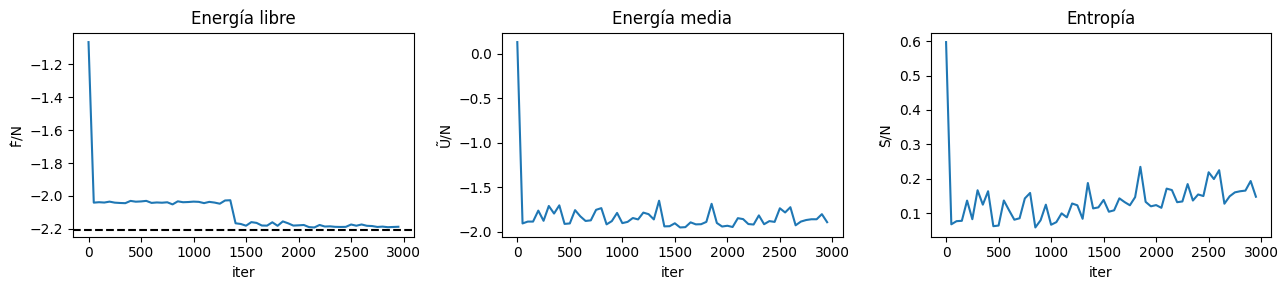

In [52]:
steps = np.arange(len(history["F"])) * 50
fig, ax = plt.subplots(1, 3, figsize=(13, 3))

ax[0].plot(steps, np.array(history["F"]) / N)
ax[0].axhline(F_B.item() / N, ls="--", c="k")
ax[0].set_xlabel("iter"); ax[0].set_ylabel("F̂/N"); ax[0].set_title("Energía libre")

ax[1].plot(steps, np.array(history["U"]) / N)
ax[1].set_xlabel("iter"); ax[1].set_ylabel("Ũ/N"); ax[1].set_title("Energía media")

ax[2].plot(steps, np.array(history["S"]) / N)
ax[2].set_xlabel("iter"); ax[2].set_ylabel("S̃/N"); ax[2].set_title("Entropía")

plt.tight_layout(); plt.show()

In [56]:
samples_eval = sample_configs(model, 4096).float()

model.train()
with torch.no_grad():
    log_q_eval = log_probability(model, samples_eval)

E_eval  = ising_energy(samples_eval, L, J, h)
f_eval  = E_eval + T * log_q_eval
F_final = f_eval.mean()
U_final = E_eval.mean()
S_final = -log_q_eval.mean()
mag     = samples_eval.mean(dim=1).abs().mean()

print(f"F̂/N   = {(F_final/N).item():.6f}   (exacto = {(F_B/N).item():.6f})")
print(f"Ũ/N   = {(U_final/N).item():.6f}")
print(f"S̃/N   = {(S_final/N).item():.6f}")
print(f"⟨|m|⟩ = {mag.item():.6f}")

F̂/N   = -2.184357   (exacto = -2.205589)
Ũ/N   = -1.778754
S̃/N   = 0.202801
⟨|m|⟩ = 0.942763


## Configuraciones generadas

Ejemplos de configuraciones $s\sim q_\theta$ dispuestas en la red $L\times L$. Rojo $=+1$, azul $=-1$. Cada título indica la magnetización $m=\frac{1}{N}\sum_i s_i$.

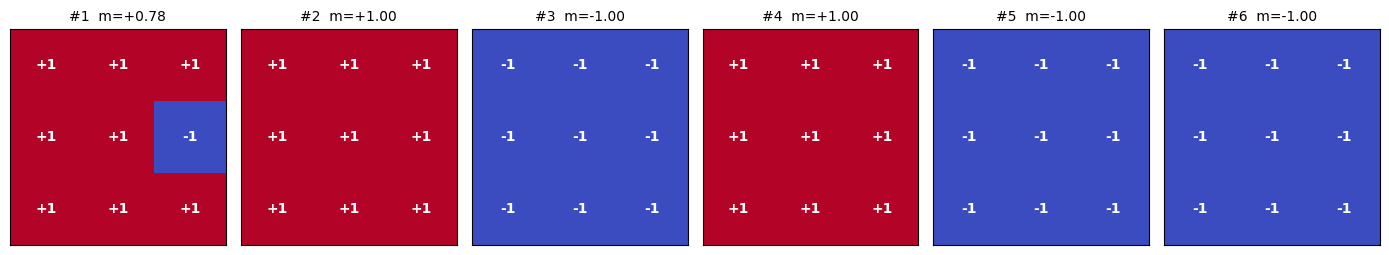

In [59]:
fig, axes = plt.subplots(1, 6, figsize=(14, 2.5))
for i in range(6):
    lat = samples_eval[i].cpu().numpy().reshape(L, L).astype(int)
    m   = lat.mean()

    ax = axes[i]
    ax.imshow(lat, cmap="coolwarm", vmin=-1, vmax=1)

    # anotar el valor del espín en cada celda
    for r in range(L):
        for c in range(L):
            ax.text(c, r, f"{lat[r, c]:+d}",
                    ha="center", va="center",
                    color="white", fontsize=10, fontweight="bold")

    ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f"#{i+1}  m={m:+.2f}", fontsize=10)

plt.tight_layout()
plt.show()